# Feature Engineering — Clasificación comercial de limón

**Objetivo:** convertir las 5 imágenes de cada fruto en variables que ayuden a clasificar (Extra, Primera, Segunda, Tercera, Fábrica), **demostrando con experimentos controlados** qué aporta cada decisión y **sin fuga de información**.

In [ ]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import fe_experimentos as fx, seleccion, firma, extraer_features as ef
from src.fe_columnas import COLS_A, COLS_C, COLS_META, columnas_para, verificar_sin_fuga
from src.fe_pipeline import construir_pipeline
from src.particion import cargar_particion, huella_particion, verificar_particion
from src.eda import normalizar_categorias, CATEGORIAS

MODO_DEMO = False
RAW  = ROOT / "data" / ("demo/raw" if MODO_DEMO else "raw")
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
EJECUTAR_ABLACIONES = True           # tarda unos minutos (3 semillas x 5 pliegues x ~20 configuraciones)
CONTROL_FUGA = True                  # incluye el experimento de control (lote como entrada)
cfg = ef.cargar_cfg()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
PAL = {"Extra": "#2e7d32", "Primera": "#7cb342", "Segunda": "#fbc02d", "Tercera": "#ef6c00", "Fabrica": "#7a1f2b"}
print("Config:", {k: cfg[k] for k in ("semillas", "cv_folds", "modelos", "conjuntos")})

Config: {'semillas': [0, 1, 2], 'cv_folds': 5, 'modelos': ['knn', 'logreg', 'rf'], 'conjuntos': ['A', 'A+B', 'A+C', 'A+B+C', 'A+B+C+S']}


## 1. Extracción de features desde las imágenes
Cada imagen produce medidas de **geometría** (ejes, área, circularidad, solidez), **color en CIELAB** sobre la superficie sana, **defectos** (manchas más oscuras que el color mediano del fruto) y **textura**. Luego se agregan por fruto con la regla del flujo: *calibre → mediana, color → media, defecto → basta una vista*.

Esta etapa **no aprende nada de los datos** (no usa medias del dataset), por eso puede hacerse antes de partir sin fuga. Si ya generaste `features_frutos.csv` se reutiliza.

In [ ]:
if not (PROC / "features_frutos.csv").exists():
    ef.main(RAW, PROC, n_jobs=1)
df = fx.cargar_datos(PROC, cfg)          # features + etiquetas + partición + features de dominio (C)
print(f"Frutos utilizables: {len(df)} | features A: {len(COLS_A)} | features C (dominio): {len(COLS_C)}")
df[["id_fruto", "lote", "fecha", "y", "subset"] + COLS_A[:5]].head()

Frutos utilizables: 320 | features A: 30 | features C (dominio): 10


,id_fruto,lote,fecha,y,subset,diam_ecu_px,diam_ecu_mm,long_polar_px,long_polar_mm,aspecto
0,LIM1,L1,20261006,Fabrica,val,463.523880,NaN,775.627533,NaN,1.655126
1,LIM10,L1,20261006,Fabrica,train,526.341629,NaN,534.844543,NaN,1.018123
2,LIM100,L1,20261006,Fabrica,train,442.558395,NaN,576.627045,NaN,1.275392
3,LIM101,L2,20261013,Extra,train,451.681030,NaN,565.306976,NaN,1.267462
4,LIM102,L2,20261013,Extra,train,461.674438,NaN,497.411987,NaN,1.031855


## 2. Validación de la extracción
Aquí SÍ se usa el estándar de referencia, pero solo para **verificar** la extracción, no como entrada. Qué buscar: calibre con MAE ≤ 1,0 mm (meta del proyecto) y sin sesgo sistemático; el color debe separar `color_panel`; el defecto debe correlacionar con `severidad_defecto_panel`.

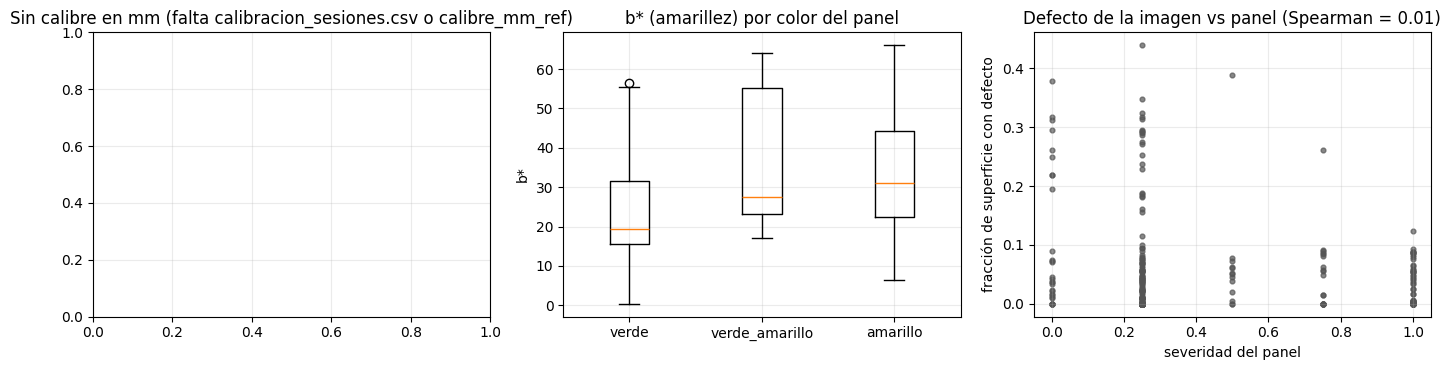

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
v = df.dropna(subset=["diam_ecu_mm", "calibre_mm_ref"])
if len(v):
    err = v["diam_ecu_mm"] - v["calibre_mm_ref"]
    axs[0].scatter(v["calibre_mm_ref"], v["diam_ecu_mm"], s=12, alpha=.7, color="#7a1f2b")
    lim = [v["calibre_mm_ref"].min() - 1, v["calibre_mm_ref"].max() + 1]; axs[0].plot(lim, lim, "k--", lw=1)
    axs[0].set_xlabel("calibre medido (mm)"); axs[0].set_ylabel("calibre de la imagen (mm)")
    axs[0].set_title(f"Calibre: MAE={err.abs().mean():.2f} mm  RMSE={np.sqrt((err**2).mean()):.2f}  sesgo={err.mean():+.2f}")
    print(f"Calibre -> MAE {err.abs().mean():.2f} mm | RMSE {np.sqrt((err**2).mean()):.2f} mm | sesgo {err.mean():+.2f} mm | meta MAE <= 1.0 mm")
else:
    axs[0].set_title("Sin calibre en mm (falta calibracion_sesiones.csv o calibre_mm_ref)")
if "color_panel" in df:
    orden = [c for c in ["verde", "verde_amarillo", "amarillo"] if c in set(df["color_panel"].dropna())]
    axs[1].boxplot([df.loc[df.color_panel == c, "b_media"].dropna() for c in orden], labels=orden)
    axs[1].set_title("b* (amarillez) por color del panel"); axs[1].set_ylabel("b*")
if "severidad_defecto_panel" in df:
    axs[2].scatter(df["severidad_defecto_panel"], df["defecto_max"], s=12, alpha=.7, color="#555")
    rho = df["defecto_max"].corr(df["severidad_defecto_panel"], method="spearman")
    axs[2].set_title(f"Defecto de la imagen vs panel (Spearman = {rho:.2f})")
    axs[2].set_xlabel("severidad del panel"); axs[2].set_ylabel("fracción de superficie con defecto")
plt.tight_layout(); plt.show()

## 3. Partición congelada
Se parte **por fruto** (70/15/15), estratificando por categoría y lote, con semilla fija. Se genera **una sola vez** (`python src/particion.py`) y se guarda en `particion.csv` con una huella (hash) que queda registrada en cada experimento. Qué buscar: ningún fruto repetido y todas las categorías, lotes y fechas presentes en train, val y test.

In [ ]:
part = cargar_particion(PROC)
print("Huella de la partición:", huella_particion(part))
problemas = verificar_particion(fx.pd.read_csv(PROC / "indice_frutos.csv", dtype={"id_fruto": str, "lote": str, "fecha": str})
                                .query("completo"), part)
print("Verificación:", "OK" if not problemas else problemas)
display(pd.crosstab(df["y"], df["subset"]).reindex(CATEGORIAS)[["train", "val", "test"]])
tr, va, te = fx.dividir(df)

Huella de la partición: f84dd42cbb16
Verificación: OK


subset,train,val,test
y,,,
Extra,77.0,16.0,16.0
Primera,71.0,15.0,15.0
Segunda,NaN,NaN,NaN
Tercera,6.0,2.0,2.0
Fabrica,70.0,15.0,15.0


## 4. Inspección de las features en TRAIN
Todo diagnóstico que dependa de estadísticos (asimetría, atípicos, faltantes) se calcula **solo con train**. Esto decide qué transformaciones del conjunto **B** tienen sentido:
- asimetría alta (> 1) → candidata a `log1p`; colas extremas → winsorización (p5–p95); atípicos → banderas; faltantes → imputación + indicador.

Candidatas a log1p (asimetria > 1 y valores >= 0): ['aspecto', 'asimetria_cv_diam', 'ped_area_ratio', 'L_media', 'b_media', 'L_p10', 'disp_b_vistas', 'defecto_max', 'defecto_media', 'n_vistas_defecto', 'mancha_max', 'n_manchas_total', 'lap_var']


,faltantes_%,asimetria,atipicos_IQR_%
ped_area_ratio,0.0,4.64,3.57
aspecto,0.0,3.31,1.79
lap_var,0.0,3.14,11.16
defecto_media,0.0,3.00,3.12
mancha_max,0.0,2.50,10.71
defecto_max,0.0,2.39,11.16
disp_b_vistas,0.0,2.15,13.39
L_media,0.0,1.77,5.80
L_p10,0.0,1.71,4.46
asimetria_cv_diam,0.0,1.71,9.82


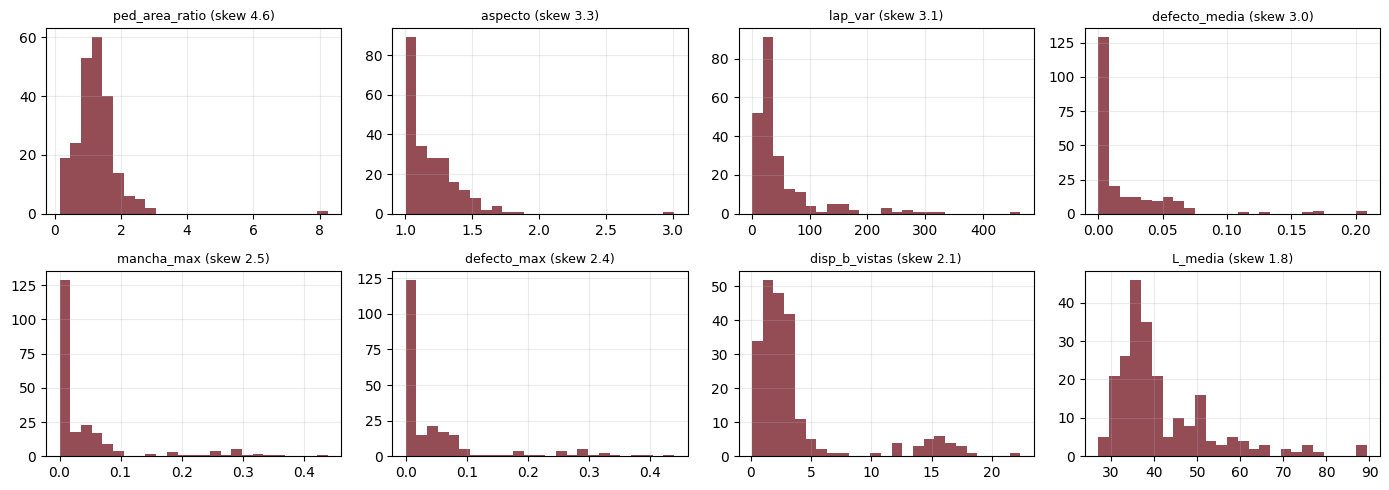

In [ ]:
X = tr[COLS_A]
diag = pd.DataFrame({"faltantes_%": 100 * X.isna().mean(), "asimetria": X.skew(),
                     "atipicos_IQR_%": 100 * ((X < X.quantile(.25) - 1.5 * (X.quantile(.75) - X.quantile(.25))) |
                                              (X > X.quantile(.75) + 1.5 * (X.quantile(.75) - X.quantile(.25)))).mean()}).round(2)
print("Candidatas a log1p (asimetria > 1 y valores >= 0):", diag.index[(diag["asimetria"] > 1) & (X.min() >= 0)].tolist())
display(diag.sort_values("asimetria", ascending=False).head(12))
cols_plot = diag["asimetria"].abs().sort_values(ascending=False).index[:8]
fig, axs = plt.subplots(2, 4, figsize=(14, 5))
for ax, c in zip(axs.ravel(), cols_plot):
    ax.hist(X[c].dropna(), bins=25, color="#7a1f2b", alpha=.8); ax.set_title(f"{c} (skew {diag.loc[c, 'asimetria']:.1f})", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Firma de datos y deriva
La **firma** (media, p10/p50/p90, varianza, % faltantes por subconjunto) deja constancia de con qué datos se corrió cada experimento y su hash se registra. Qué buscar:
- **Deriva entre subconjuntos** (KS, p < 0,01): si train y val/test difieren en alguna feature, las métricas no son comparables.
- **Deriva por lote/fecha** (|SMD| > 0,5): si un lote se distingue por una feature (p. ej. brillo o nitidez), existe riesgo de que el modelo aprenda el **contexto** y no el fruto.

Huella de la firma de datos: 8ddb602dcd90


,n,faltantes_%,media,std,varianza,p10,p50,p90
diam_ecu_mm,0,100.0,NaN,NaN,NaN,NaN,NaN,NaN
L_media,224,0.0,41.893,11.529,132.919,31.435,37.752,57.845
b_media,224,0.0,25.092,12.322,151.843,13.454,20.804,41.211
defecto_max,224,0.0,0.050,0.087,0.008,0.000,0.004,0.175


Features con deriva train vs val/test (p<0.01): 0 de 70 comparaciones


,variable,vs_train,KS,p_valor,deriva
23,L_media,test,0.187500,0.109437,False
37,L_p90,test,0.183036,0.125209,False
33,b_std,test,0.175595,0.155565,False
40,disp_b_vistas,val,0.172619,0.169235,False
31,a_std,test,0.160714,0.233579,False
41,disp_b_vistas,test,0.157738,0.252226,False


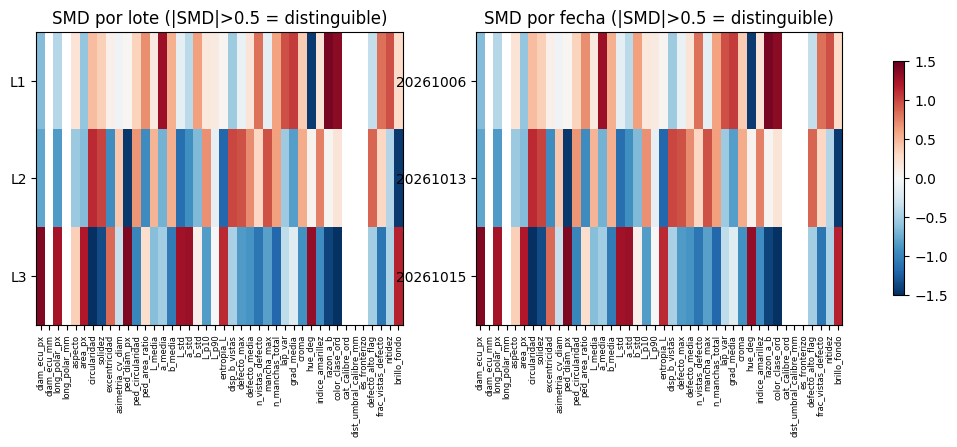

In [ ]:
cols_f = columnas_para({"A", "C"})
firmas, h = firma.firma_por_subconjunto(df, cols_f)
print("Huella de la firma de datos:", h)
display(firmas["train"].loc[["diam_ecu_mm", "L_media", "b_media", "defecto_max"]].round(3))
d = firma.deriva_entre_subconjuntos(df, cols_f)
print(f"Features con deriva train vs val/test (p<0.01): {int(d['deriva'].sum())} de {len(d)} comparaciones")
display(d.head(6))
cols_ctx = cols_f + ["nitidez", "brillo_fondo"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, g in zip(axs, ["lote", "fecha"]):
    smd = firma.deriva_por_grupo(df, cols_ctx, g)
    im = ax.imshow(smd.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_yticks(range(len(smd))); ax.set_yticklabels(smd.index); ax.set_xticks(range(smd.shape[1]))
    ax.set_xticklabels(smd.columns, rotation=90, fontsize=6); ax.set_title(f"SMD por {g} (|SMD|>0.5 = distinguible)"); ax.grid(False)
plt.colorbar(im, ax=axs, shrink=.8); plt.show()

## 6. Selección y diagnóstico de variables
- **Relevancia:** información mutua y F de ANOVA frente a la categoría.
- **Redundancia:** pares con |r| > 0,95 (X1 vs X2).
- **Colinealidad:** VIF (> 10 = problemática; relevante para regresión logística).
Estas listas **informan**; la selección que se evalúa en los experimentos (conjunto S) se ajusta *dentro* de cada pliegue para no contaminar la validación cruzada.

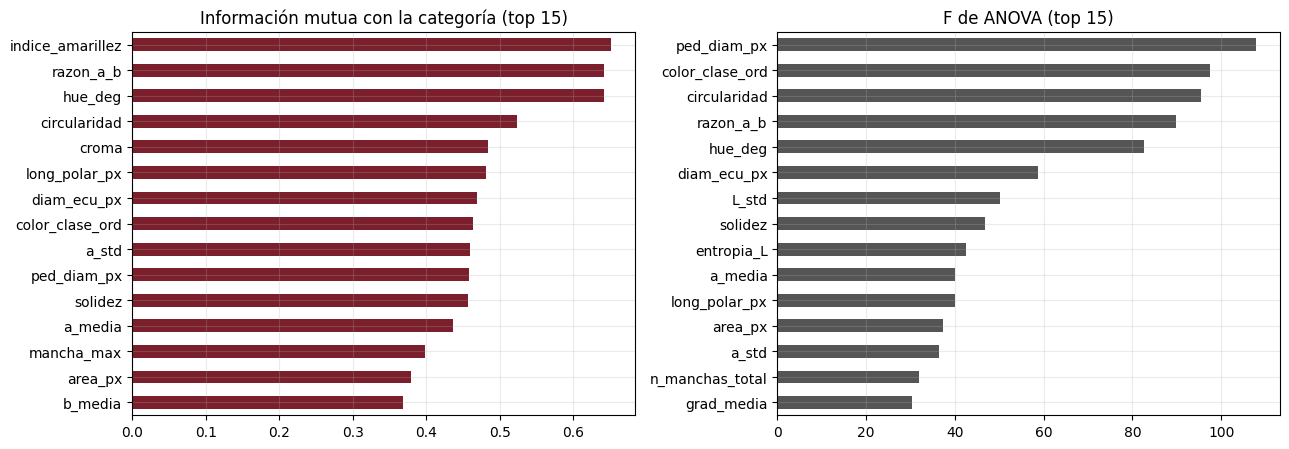

Pares muy correlacionados (|r| > 0.95):


,var_1,var_2,|r|
3,n_vistas_defecto,frac_vistas_defecto,1.000000
4,hue_deg,razon_a_b,0.996468
1,b_media,croma,0.993522
2,defecto_max,mancha_max,0.988578
0,L_media,L_p10,0.970643


VIF > 10: 26 de 35


,VIF
frac_vistas_defecto,1000000.0
n_vistas_defecto,1000000.0
L_p10,782.0
hue_deg,616.2
razon_a_b,556.6
L_media,501.1
b_media,407.5
croma,404.6


VIF iterativo: se conservarían 26 de 40 variables
Primeras eliminadas: [('frac_vistas_defecto', 1000000.0), ('L_p10', 782.0328173863437), ('hue_deg', 612.2568464812302), ('b_media', 330.4748576096709), ('L_media', 317.1259695232026)]


In [ ]:
Xs = tr[columnas_para({"A", "C"})]
mi = seleccion.ranking_mi(Xs, tr["y"]); f = seleccion.anova_f(Xs, tr["y"])
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
mi.head(15).iloc[::-1].plot.barh(ax=axs[0], color="#7a1f2b"); axs[0].set_title("Información mutua con la categoría (top 15)")
f.head(15).iloc[::-1].plot.barh(ax=axs[1], color="#555"); axs[1].set_title("F de ANOVA (top 15)")
plt.tight_layout(); plt.show()
print("Pares muy correlacionados (|r| > 0.95):"); display(seleccion.pares_correlacionados(Xs, 0.95).head(10))
v = seleccion.vif(Xs); print("VIF > 10:", int((v > 10).sum()), "de", int(v.notna().sum())); display(v.head(8).round(1).to_frame())
conservadas, eliminadas = seleccion.vif_iterativo(Xs, 10.0)
print(f"VIF iterativo: se conservarían {len(conservadas)} de {Xs.shape[1]} variables"); print("Primeras eliminadas:", eliminadas[:5])

## 7. Ablaciones de Feature Engineering
| Configuración | Qué cambia respecto a la anterior |
|---|---|
| `REF|dummy` | Referencia: siempre la clase mayoritaria (piso de desempeño) |
| `A` | Variables originales (+ imputación por mediana y escalado: base común) |
| `A+B` | + winsorización p5–p95, log1p a asimétricas, banderas de atípicos y faltantes, ángulo de matiz en sen/cos |
| `A+C` | + features de dominio (croma, matiz, amarillez, distancia a umbrales de calibre, clase de color ordinal…) |
| `A+B+C` | ambas |
| `A+B+C+S` | + filtro de colinealidad (|r| > 0,95) |
| `A_sin_escala` | efecto del escalado en kNN / regresión logística |
| `CONTROL_FUGA` | añade `lote` como entrada: si mejora mucho, hay atajo de contexto |

In [ ]:
if EJECUTAR_ABLACIONES:
    res, RUN_ID, cfg = fx.ejecutar(PROC, cfg, control_fuga=CONTROL_FUGA, verbose=False)
    print("Corrida registrada:", RUN_ID, "->", ROOT / "logs" / "fe_runs" / RUN_ID)
else:
    res = pd.read_csv(sorted((ROOT / "logs" / "fe_runs").glob("*/resultados.csv"))[-1])
tabla = res[["config", "n_features_out", "cv_f1_macro_media", "cv_f1_macro_std", "cv_bal_acc_media", "cv_recall_pos_media",
             "cv_prauc_pos_media", "val_f1_macro", "cv_fit_s_media", "latencia_total_ms_fruto", "avisos_no_convergencia"]].round(3)
display(tabla)

In [ ]:
r = res[~res.config.str.startswith(("REF", "CONTROL", "A_sin"))].copy()
r["conj"], r["modelo"] = r.config.str.split("|").str[0], r.config.str.split("|").str[1]
modelos = list(r.modelo.unique()); conjs = list(dict.fromkeys(r.conj)); w = .8 / len(modelos)
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(modelos):
    s = r[r.modelo == m].set_index("conj").loc[conjs]
    ax.bar(np.arange(len(conjs)) + i * w, s.cv_f1_macro_media, w, yerr=s.cv_f1_macro_std, capsize=3, label=m)
ref = res.loc[res.config.str.startswith("REF"), "cv_f1_macro_media"].iloc[0]
ax.axhline(ref, color="k", ls=":", label="referencia (dummy)")
ax.set_xticks(np.arange(len(conjs)) + w * (len(modelos) - 1) / 2); ax.set_xticklabels(conjs)
ax.set_ylabel("F1 macro (CV en train)"); ax.set_title("Ablación de Feature Engineering (media ± desv. entre pliegues y semillas)"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

## 8. Importancia por permutación

Se toma la mejor configuración por **CV en train**, se reajusta con train y se mide, **en validación**, cuánto cae el F1 macro al barajar cada variable. Qué buscar: variables cuya permutación casi no cambia nada (candidatas a eliminar) y variables dominantes (verificar que tengan sentido físico: calibre, color, defecto).

In [ ]:
cand = res[~res.config.str.startswith(("REF", "CONTROL", "A_sin"))].sort_values("cv_f1_macro_media", ascending=False).iloc[0]
conj, modelo = cand.config.split("|")
print("Mejor configuración por CV en train:", cand.config, f"(F1 macro CV = {cand.cv_f1_macro_media:.3f})")
cols = [c for c in columnas_para(set(conj.split("+"))) if tr[c].notna().any()]
pipe = construir_pipeline(cols, conj, modelo, cfg["semillas"][0], cfg).fit(tr[cols], tr["y"])
imp = seleccion.importancia_permutacion(pipe, va[cols], va["y"], n_repeats=10)
imp.head(12).iloc[::-1]["caida_f1"].plot.barh(xerr=imp.head(12).iloc[::-1]["std"], color="#7a1f2b", figsize=(7, 4))
plt.title("Caída de F1 macro al permutar (validación)"); plt.tight_layout(); plt.show()

## 9. Control de fuga
Se compara una configuración con la misma + `lote` como entrada. **Si `lote` mejora claramente las métricas, el contexto predice la categoría** y habría que rediseñar la captura o la partición. Si no cambia (como se espera), el lote no es un atajo.

In [ ]:
if CONTROL_FUGA:
    for m in ["logreg", "rf"]:
        base, ctrl = res[res.config == f"A|{m}"].iloc[0], res[res.config == f"CONTROL_FUGA_lote|{m}"].iloc[0]
        d = ctrl.cv_f1_macro_media - base.cv_f1_macro_media
        print(f"{m:7s} A: {base.cv_f1_macro_media:.3f} ± {base.cv_f1_macro_std:.3f} | A + lote: {ctrl.cv_f1_macro_media:.3f} ± {ctrl.cv_f1_macro_std:.3f} "
              f"| diferencia {d:+.3f} -> {'POSIBLE ATAJO' if d > base.cv_f1_macro_std else 'sin evidencia de atajo'}")